Step 1: Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


Explanation:
- Pandas: Data manipulation.
- NumPy: Numerical calculations.
- Matplotlib and Seaborn: Visualization.
- Scikit-learn: Dataset loading, splitting, model training and evaluation.

Step 2: Load the dataset

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (20640, 9)


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


In [7]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [8]:
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Explanation: This step helps us understand the dataset structure, data types, missing values, duplicates and numerical distributions.

Step 3: Select input features (X) and target (y)
We will use:
- X = MedInc (Median Income)
- y = MedHouseVal (Median House Value)

In [10]:
X = df[['MedInc']]

y = df['MedHouseVal']

print("Input Feature (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Input Feature (X):


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462



Target Variable (y):


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


X Shape: (20640, 1)
y Shape: (20640,)


Explanation :Median income is selected as the input feature because areas with higher median income may have higher median house values. Median house value is selected as the target variable because it is the continuous numerical value we want to predict.

Step 4: Visualize the relationship between income and house price

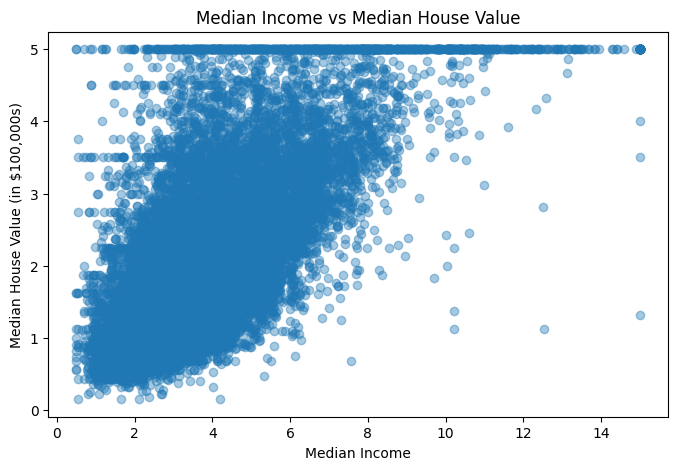

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['MedInc'],
    y,
    alpha=0.4
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (in $100,000s)")

plt.show()

Observations :
1. The scatter plot generally shows a positive relationship between median income and house value.
2. Areas with higher median income tend to have higher median house values.
3. The relationship is not perfectly linear because other factors also influence house prices.
A visible relationship does not prove that income causes higher house prices.

Step 5: Split the dataset into training and testing sets
We will divide the data into:
- 80% Training data.
- 20% Testing data.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (16512, 1)
Testing Data: (4128, 1)
Training Target: (16512,)
Testing Target: (4128,)


Explanation:

Training data is used to teach the model the relationship between income and house prices. Testing data is used to evaluate how accurately the model predicts prices for unseen observations.

The testing data is not used during model training.

Step 6: Train the Linear Regression model

In [13]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")
coefficient = model.coef_[0]

intercept = model.intercept_

print("Coefficient:", coefficient)

print("Intercept:", intercept)
print(
    f"House Price = {intercept:.4f} "
    f"+ ({coefficient:.4f} * Median Income)"
)

Linear Regression Model Trained Successfully!
Coefficient: 0.4193384939381271
Intercept: 0.4445972916907879
House Price = 0.4446 + (0.4193 * Median Income)


Explanation:
- Coefficient (slope): Indicates how much the predicted house value changes for a one-unit increase in median income.
- Intercept: Predicted house value when median income is zero.
The Linear Regression equation is:
\[
y = mx+c
\]

Where:
- y = Predicted house value.
- m = Coefficient.
- x = Median income.
- c = Intercept.

Step 7: Generate predictions
Use the trained model to predict the test dataset values.

In [14]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [15]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted House Prices:")

display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


Explanation:

The actual price represents the original house value, while the predicted price represents the value estimated by the Linear Regression model.

Some predictions may be close to the actual values, while others may have noticeable errors.

Remember: These are predictions on the test dataset, not training data.

Step 8: Evaluate the Linear Regression model
Now calculate the regression evaluation metrics.

In [16]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

MODEL EVALUATION
MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R2 Score: 0.45885918903846656


Understand the evaluation metrics:
Metric	Meaning
MAE	Average absolute prediction error
MSE	Average squared prediction error
RMSE	Square root of MSE, in target units
R²	Measures performance compared with predicting the mean

How to interpret:
- Lower MAE means smaller average absolute errors.
- Lower MSE means smaller squared errors.
- Lower RMSE means better prediction accuracy in the target's units.
- Higher R² generally indicates a better fit relative to a mean-based baseline.
R² can also be negative when the model performs worse than the mean-based baseline on test data.

For this dataset, remember that all errors are in units of $100,000 for the house value. For example, an RMSE of 0.8 represents approximately $80,000.

Step 9: Visualize actual versus predicted prices
Create a scatter plot comparing actual and predicted values.

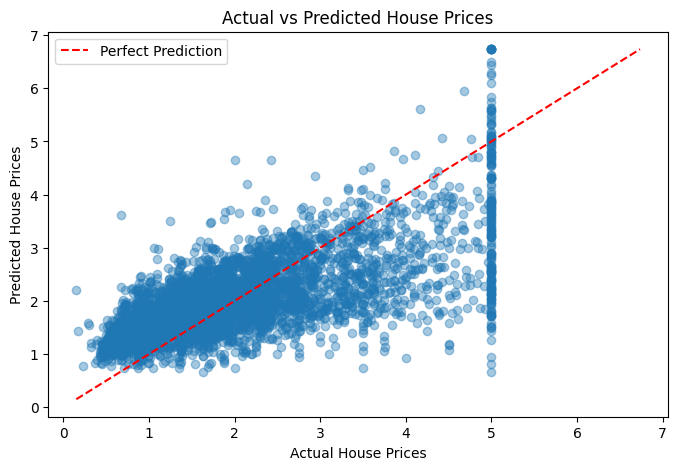

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect Prediction'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.legend()
plt.show()

Observations :
1. Points close to the red reference line represent more accurate predictions.
2. Points far from the line indicate larger prediction errors.
3. The model may not accurately capture all variations in house prices because it uses only one input feature.

Step 10: Predict a new house price
Now use the trained model to predict the price for a new example.

We'll use the median income from the training dataset as the new input value. This is a reasonable value within the observed training range.

In [18]:
# New example

new_income = pd.DataFrame({
    'MedInc': [X_train['MedInc'].median()]
})

# Predict house value
new_prediction = model.predict(new_income)

print("New House Prediction")

print("Median Income:", new_income['MedInc'].iloc[0])

print("Predicted House Value:",
      new_prediction[0])

print("Predicted Price in Dollars:",
      new_prediction[0] * 100000)

New House Prediction
Median Income: 3.5458
Predicted House Value: 1.9314877234965988
Predicted Price in Dollars: 193148.77234965988


Explanation:

The trained Linear Regression model predicts the house value based on the supplied median income.

The predicted value is expressed in units of $100,000. Multiplying the result by 100,000 converts it into dollars.

Conclusion

In this activity, the California Housing dataset was used to develop a Simple Linear Regression model for house price prediction.

The dataset was inspected to understand its structure, features, data types and statistical properties. Median Income (MedInc) was selected as the input feature, and Median House Value (MedHouseVal) was selected as the target variable.

The dataset was divided into 80% training data and 20% testing data. A Linear Regression model was trained using the training dataset to learn the relationship between median income and house value.

The model generated predictions on unseen testing data. Its performance was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R-squared (R²).

Scatter plots were used to visualize the relationship between median income and house value and to compare actual and predicted prices.

Finally, the trained model was used to predict a new house value.

Thus, this activity demonstrated the basic working of supervised learning using Linear Regression. However, house prices depend on several factors, and using only median income limits the prediction accuracy of the model.